1. download CIFAR-10
2. implement CNN
3. Loss, hyperparameters

In [1]:
# !tar -xzf cifar-10-python.tar.gz

In [2]:
def unpickle(file):
    import pickle
    with open(file, 'rb') as fo:
        dict = pickle.load(fo, encoding='bytes')
    return dict

data = unpickle(r'cifar-10-batches-py\data_batch_1')

C:\Users\User\AppData\Local\Temp\ipykernel_15316\2973063824.py:4: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  dict = pickle.load(fo, encoding='bytes')


In [3]:
for k, v in data.items():
    if k == b'batch_label':
        print(k, v)
        continue
    print(k, len(v))

b'batch_label' b'training batch 1 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000


In [4]:
import os
batch_names = ('data_batch_1', 'data_batch_2', 'data_batch_3', 'data_batch_4', 'data_batch_5')
for b in batch_names:
    data = unpickle(os.path.join('cifar-10-batches-py', b))
    print(b)
    for k, v in data.items():
        if k == b'batch_label':
            print(k, v)
        else:
            print(k, len(v))
    

data_batch_1
b'batch_label' b'training batch 1 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000
data_batch_2
b'batch_label' b'training batch 2 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000
data_batch_3
b'batch_label' b'training batch 3 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000
data_batch_4
b'batch_label' b'training batch 4 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000
data_batch_5
b'batch_label' b'training batch 5 of 5'
b'labels' 10000
b'data' 10000
b'filenames' 10000


C:\Users\User\AppData\Local\Temp\ipykernel_15316\2973063824.py:4: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  dict = pickle.load(fo, encoding='bytes')


In [5]:
data[b'labels'][0], data[b'filenames'][0], data[b'data'][0]

(1,
 b'compact_car_s_001706.png',
 array([255, 252, 253, ..., 173, 231, 248], shape=(3072,), dtype=uint8))

In [6]:
meta = unpickle(r'cifar-10-batches-py\batches.meta')
for k, v in meta.items():
    print(k, v)

b'num_cases_per_batch' 10000
b'label_names' [b'airplane', b'automobile', b'bird', b'cat', b'deer', b'dog', b'frog', b'horse', b'ship', b'truck']
b'num_vis' 3072


In [7]:
import random
import numpy as np
import torch

config = {
    "seed": 42,
    "blocks_per_stage": (2, 2, 2),
    "channels_per_stage": (16, 32, 64),
    "batch_size": 128,
    "zoom_scale": (0.9, 1.1),
    "zoom_probability": 0.5,
    "num_epochs": 15,
    "learning_rates": (0.03, 0.1),
    "momentum": 0.9,
    "weight_decay": 5e-4,
    "min_learning_rate": 1e-4,
    "validation_per_class": 500,
    "tuning_epochs": 3,
    "tuning_train_size": 10000,
    "tuning_validation_size": 2000,
}

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(config["seed"])
for name, value in config.items():
    print(f"{name}: {value}")

seed: 42
blocks_per_stage: (2, 2, 2)
channels_per_stage: (16, 32, 64)
batch_size: 128
zoom_scale: (0.9, 1.1)
zoom_probability: 0.5
num_epochs: 15
learning_rates: (0.03, 0.1)
momentum: 0.9
weight_decay: 0.0005
min_learning_rate: 0.0001
validation_per_class: 500
tuning_epochs: 3
tuning_train_size: 10000
tuning_validation_size: 2000


In [8]:
import os
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision.transforms import v2


class CIFAR10Dataset(Dataset):
    def __init__(self, batch_names=(), transform=None, *, images=None, labels=None):
        if images is None:
            batches = [unpickle(name) for name in batch_names]
            images = torch.from_numpy(np.concatenate([b[b"data"] for b in batches])).reshape(-1, 3, 32, 32)
            labels = torch.tensor([label for b in batches for label in b[b"labels"]], dtype=torch.long)
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        image = self.images[index]
        if self.transform is not None:
            image = self.transform(image)
        return image, self.labels[index]


full_train_dataset = CIFAR10Dataset(
    [os.path.join("cifar-10-batches-py", f"data_batch_{i}") for i in range(1, 6)]
)
num_classes = len(meta[b"label_names"])
split_generator = torch.Generator().manual_seed(config["seed"])
train_indices, validation_indices = [], []
for class_id in range(num_classes):
    indices = (full_train_dataset.labels == class_id).nonzero(as_tuple=True)[0]
    indices = indices[torch.randperm(len(indices), generator=split_generator)]
    count = config["validation_per_class"]
    if not 0 < count < len(indices):
        raise ValueError("validation_per_class must leave images in both splits")
    validation_indices.append(indices[:count])
    train_indices.append(indices[count:])
train_indices = torch.cat(train_indices)
validation_indices = torch.cat(validation_indices)

train_images = full_train_dataset.images[train_indices]
validation_images = full_train_dataset.images[validation_indices]
scaled_images = train_images.to(torch.float32) / 255
channel_mean = scaled_images.mean(dim=(0, 2, 3))
channel_std = scaled_images.std(dim=(0, 2, 3), correction=0)
del scaled_images

train_transform = v2.Compose([
    v2.RandomCrop(32, padding=4),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True),
    # v2.RandomApply([
    #     v2.RandomAffine(
    #         degrees=0,
    #         scale=config["zoom_scale"],
    #         interpolation=v2.InterpolationMode.BILINEAR,
    #         fill=tuple(channel_mean.tolist()),
    #     ),
    # ], p=config["zoom_probability"]),
    v2.Normalize(mean=channel_mean.tolist(), std=channel_std.tolist()),
])
test_transform = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=channel_mean.tolist(), std=channel_std.tolist()),
])
train_dataset = CIFAR10Dataset(
    images=train_images, labels=full_train_dataset.labels[train_indices], transform=train_transform
)
validation_dataset = CIFAR10Dataset(
    images=validation_images, labels=full_train_dataset.labels[validation_indices], transform=test_transform
)
test_dataset = CIFAR10Dataset(
    [os.path.join("cifar-10-batches-py", "test_batch")], transform=test_transform
)
print("Normalization mean:", channel_mean.tolist())
print("Normalization std:", channel_std.tolist())

C:\Users\User\AppData\Local\Temp\ipykernel_15316\2973063824.py:4: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  dict = pickle.load(fo, encoding='bytes')


Normalization mean: [0.4912806749343872, 0.48192453384399414, 0.44612812995910645]
Normalization std: [0.24704591929912567, 0.2434772551059723, 0.2615528106689453]


Train
	Total: torch.Size([45000, 3, 32, 32]); labels: torch.Size([45000])
	One item: torch.Size([3, 32, 32]), torch.float32; label: torch.Size([]), torch.int64
Validation
	Total: torch.Size([5000, 3, 32, 32]); labels: torch.Size([5000])
	One item: torch.Size([3, 32, 32]), torch.float32; label: torch.Size([]), torch.int64
Test
	Total: torch.Size([10000, 3, 32, 32]); labels: torch.Size([10000])
	One item: torch.Size([3, 32, 32]), torch.float32; label: torch.Size([]), torch.int64


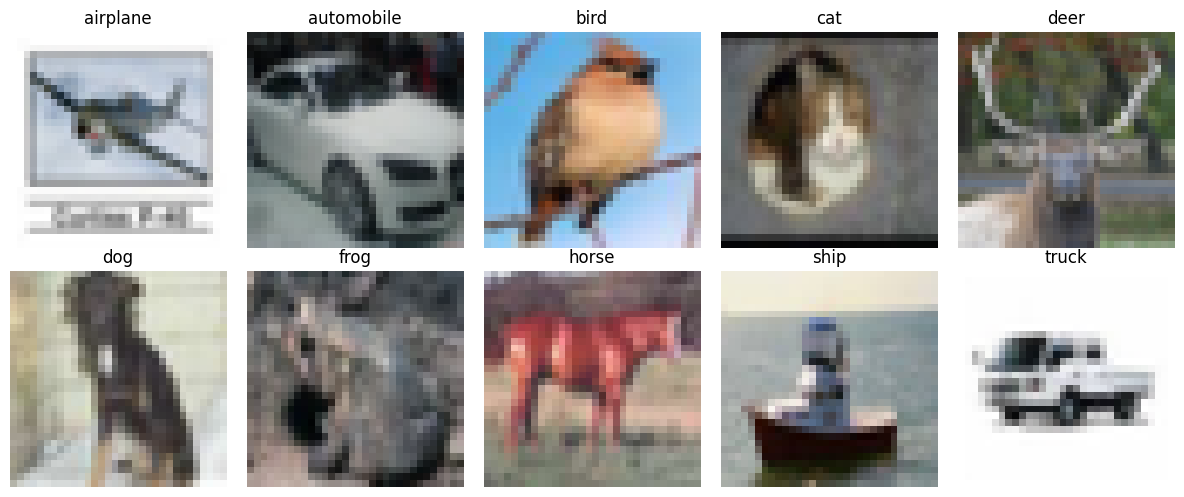

In [9]:
import matplotlib.pyplot as plt

for name, dataset in (("Train", train_dataset), ("Validation", validation_dataset), ("Test", test_dataset)):
    image, label = dataset[0]
    print(name)
    print(f"\tTotal: {dataset.images.shape}; labels: {dataset.labels.shape}")
    print(f"\tOne item: {image.shape}, {image.dtype}; label: {label.shape}, {label.dtype}")

class_names = [name.decode("utf-8") for name in meta[b"label_names"]]
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for class_id, ax in enumerate(axes.flat):
    index = (train_dataset.labels == class_id).nonzero(as_tuple=True)[0][0].item()
    image = train_dataset.images[index]
    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[class_id])
    ax.axis("off")

plt.tight_layout()
plt.show()

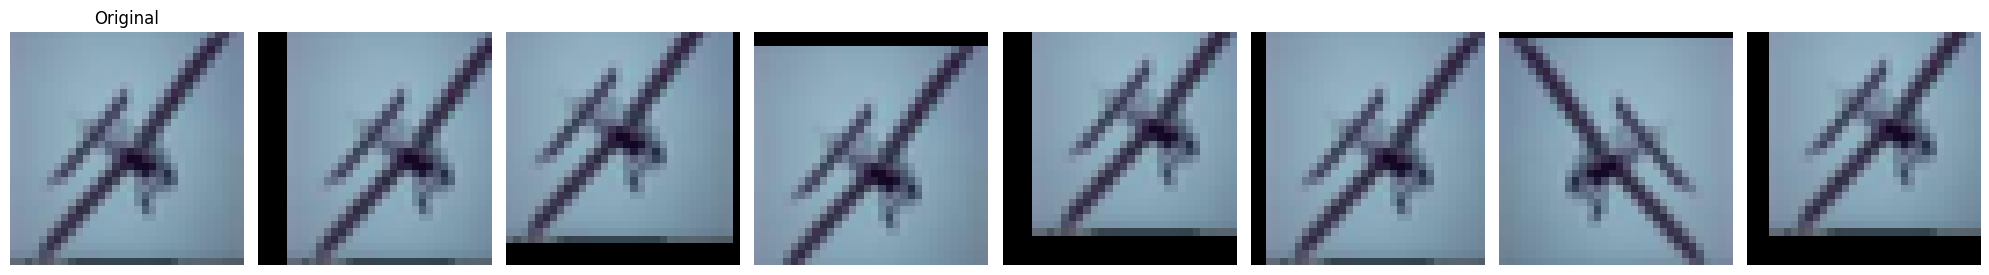

In [10]:
sample_index = 42
original_image = train_dataset.images[sample_index]
sample_label = train_dataset.labels[sample_index].item()

fig, axes = plt.subplots(1, 8, figsize=(20, 5))
axes = axes.ravel()
axes[0].imshow(original_image.permute(1, 2, 0), interpolation="nearest")
axes[0].set_title("Original")

for number, axis in enumerate(axes[1:8], start=1):
    transformed_image, label = train_dataset[sample_index]
    display_image = (
        transformed_image * channel_std.reshape(-1, 1, 1)
        + channel_mean.reshape(-1, 1, 1)
    ).clamp(0, 1)

    axis.imshow(display_image.permute(1, 2, 0), interpolation="nearest")

for axis in axes:
    axis.axis("off")
plt.tight_layout()
plt.show()

In [11]:
train_generator = torch.Generator().manual_seed(config["seed"])
train_loader = DataLoader(
    train_dataset,
    batch_size=config["batch_size"],
    shuffle=True,
    generator=train_generator,
)
validation_loader = DataLoader(
    validation_dataset, batch_size=config["batch_size"], shuffle=False
)
test_loader = DataLoader(test_dataset, batch_size=config["batch_size"], shuffle=False)

In [12]:
import numpy as np
# rng = np.random.default_rng(0)
# AlexNet, VGG, GoogLeNet, ResNet
class ConvolutionalNeuralNetwork(torch.nn.Module):
    def __init__(self):
        super(ConvolutionalNeuralNetwork, self).__init__()
        # Свертка. Размер результирующей карты признаков:
        # 10 x ((28-3)/1+1) x ((28-3)/1+1) = 10 x 26 x 26
        self.conv = torch.nn.Conv2d(
            in_channels = 3, out_channels = 10, kernel_size = 3, stride = 1
        )
        # Функция активации. Размер результирующей карты признаков:
        # 10 x 26 x 26
        self.activation = torch.nn.ReLU()
        # Пространственное объединение по максимуму. Размер результирующей карты признаков:
        # 10 x ((26-2)/1+1) x ((26-2)/1+1) = 10 x 25 x 25
        self.pooling = torch.nn.MaxPool2d(kernel_size = 2, stride = 1)
        # Создание полносвязного слоя (softmax включается в вычисление кросс-энтропии)
        self.linear = torch.nn.Linear(10 * 29 * 29, 10)

        # torch.nn.init.dirac(self.conv.weight)
        # torch.nn.init.xavier_normal_(self.linear.weight, gain=torch.nn.init.calculate_gain("relu"))


    
    def forward(self, x):
        out = self.conv(x)
        out = self.activation(out)
        out = self.pooling(out)
        # Изменение формата хранения тензора из (B, C, W, H) в (B, C*W*H)
        out = out.view(out.size(0), -1)
        # print(out.shape)
        out = self.linear(out)
        return out # softmax содержится внутри cross-entropy 

cnn_model = ConvolutionalNeuralNetwork()

# batch size, channels, width, height
cnn_model(torch.rand(1, 3, 32, 32)) 
cnn_model

ConvolutionalNeuralNetwork(
  (conv): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1))
  (activation): ReLU()
  (pooling): MaxPool2d(kernel_size=2, stride=1, padding=0, dilation=1, ceil_mode=False)
  (linear): Linear(in_features=8410, out_features=10, bias=True)
)

In [13]:
import torch.nn as nn


# https://www.kaggle.com/code/spellsharp/resnets-an-intuitive-approach
class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1, downsample=None):
        super(ResidualBlock, self).__init__()

        self.conv1 = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            stride=stride,
            padding=1,
            kernel_size=3,
            bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(
            in_channels=out_channels,
            out_channels=out_channels,
            stride=1,
            padding=1,
            kernel_size=3,
            bias=False,
        )
        self.bn2 = nn.BatchNorm2d(out_channels)
        self.downsample = downsample
        self.relu = nn.ReLU(inplace=True)

    def forward(self, x):
        identity = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)  # NOTE: MYEDIT
        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            identity = self.downsample(x)

        out += identity
        out = self.relu(out)

        return out


def make_layer(block, in_channels, out_channels, blocks, stride=1):
    downsample = None
    if stride != 1 or in_channels != out_channels:
        downsample = nn.Sequential(
            nn.Conv2d(
                in_channels, out_channels, kernel_size=1, stride=stride, bias=False
            ),
            nn.BatchNorm2d(out_channels),
        )
    layers = []
    layers.append(
        block(in_channels, out_channels, stride=stride, downsample=downsample)
    )
    for _ in range(1, blocks):
        layers.append(block(out_channels, out_channels))

    return nn.Sequential(*layers)


class ResNet(nn.Module):
    def __init__(self, block, layers, channels, num_classes=10):
        super().__init__()
        if not layers or len(layers) != len(channels):
            raise ValueError("Each stage needs a block count and a channel width")
        if any(not isinstance(v, int) or v <= 0 for v in (*layers, *channels)):
            raise ValueError(
                "Block counts and channel widths must be positive integers"
            )
        self.conv1 = nn.Conv2d(
            3, channels[0], kernel_size=3, stride=1, padding=1, bias=False
        )
        self.bn1 = nn.BatchNorm2d(channels[0])
        self.relu = nn.ReLU(inplace=True)
        stages = []
        in_channels = channels[0]
        for stage, (blocks, out_channels) in enumerate(zip(layers, channels)):
            stages.append(
                make_layer(
                    block,
                    in_channels,
                    out_channels,
                    blocks,
                    stride=1 if stage == 0 else 2,
                )
            )
            in_channels = out_channels
        self.stages = nn.Sequential(*stages)
        self.avgpool = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(channels[-1], num_classes)

    def forward(self, x):
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)

        x = self.stages(x)

        x = self.avgpool(x)
        x = torch.flatten(x, 1)
        x = self.fc(x)

        return x


def build_model():
    return ResNet(
        ResidualBlock,
        layers=config["blocks_per_stage"],
        channels=config["channels_per_stage"],
        num_classes=num_classes,
    )

In [14]:
cnn_model = build_model()
main_path_layers = 2 + 2 * sum(config["blocks_per_stage"])
print(f"Main-path convolutional + linear layers: {main_path_layers}")
print(f"Parameters: {sum(p.numel() for p in cnn_model.parameters()):,}")
print(cnn_model)

Main-path convolutional + linear layers: 14
Parameters: 175,258
ResNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (stages): Sequential(
    (0): Sequential(
      (0): ResidualBlock(
        (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
      )
      (1): ResidualBlock(
        (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (con

In [15]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


In [16]:
import time

loss_function = torch.nn.CrossEntropyLoss()


def run_epoch(model, data_loader, optimizer=None):
    training = optimizer is not None
    was_training = model.training
    model.train(training)
    running_loss, correct, n = 0.0, 0, 0
    try:
        with torch.set_grad_enabled(training):
            for images, labels in data_loader:
                images, labels = images.to(device), labels.to(device)
                if training:
                    optimizer.zero_grad()
                outputs = model(images)
                loss = loss_function(outputs, labels)
                if training:
                    loss.backward()
                    optimizer.step()
                batch_size = labels.size(0)
                n += batch_size
                running_loss += loss.item() * batch_size
                correct += (outputs.argmax(1) == labels).sum().item()
    finally:
        model.train(was_training)
    return {"loss": running_loss / n, "accuracy": correct / n}


def get_accuracy(data_loader, model):
    result = run_epoch(model, data_loader)
    return result["accuracy"], result["loss"]


def make_optimizer(model, learning_rate):
    return torch.optim.SGD(
        model.parameters(), lr=learning_rate,
        momentum=config["momentum"], weight_decay=config["weight_decay"],
    )


# Fixed, class-balanced subsets for a bounded learning-rate search.
def balanced_subset(dataset, requested_size):
    if not 0 < requested_size <= len(dataset) or requested_size % num_classes:
        raise ValueError("Tuning subset size must fit the dataset and divide evenly by class count")
    generator = torch.Generator().manual_seed(config["seed"])
    indices = []
    for class_id in range(num_classes):
        candidates = (dataset.labels == class_id).nonzero(as_tuple=True)[0]
        selected = candidates[torch.randperm(len(candidates), generator=generator)]
        count = requested_size // num_classes
        if count > len(selected):
            raise ValueError("Not enough images of a class for a balanced subset")
        indices.extend(selected[:count].tolist())
    return Subset(dataset, indices)


tuning_generator = torch.Generator()
tuning_train_loader = DataLoader(
    balanced_subset(train_dataset, config["tuning_train_size"]),
    batch_size=config["batch_size"], shuffle=True, generator=tuning_generator,
)
tuning_validation_loader = DataLoader(
    balanced_subset(validation_dataset, config["tuning_validation_size"]),
    batch_size=config["batch_size"], shuffle=False,
)
tuning_results = []
for learning_rate in config["learning_rates"]:
    set_seed(config["seed"])
    tuning_generator.manual_seed(config["seed"])
    candidate = build_model().to(device)
    candidate_optimizer = make_optimizer(candidate, learning_rate)
    for epoch in range(config["tuning_epochs"]):
        started = time.perf_counter()
        train_result = run_epoch(candidate, tuning_train_loader, candidate_optimizer)
        validation_result = run_epoch(candidate, tuning_validation_loader)
        print(
            f"Tuning lr={learning_rate}: epoch {epoch + 1}/{config['tuning_epochs']} "
            f"train_loss={train_result['loss']:.4f} train_accuracy={train_result['accuracy']:.4f} "
            f"val_loss={validation_result['loss']:.4f} val_accuracy={validation_result['accuracy']:.4f} "
            f"elapsed={time.perf_counter() - started:.1f}s", flush=True,
        )
    tuning_results.append({"learning_rate": learning_rate, **validation_result})
    del candidate_optimizer, candidate
selected = max(tuning_results, key=lambda result: (result["accuracy"], -result["loss"]))
learning_rate = selected["learning_rate"]
print("Tuning results:", tuning_results)
print(f"Selected learning rate: {learning_rate} (validation accuracy={selected['accuracy']:.2%})")

Tuning lr=0.03: epoch 1/3 train_loss=1.9054 train_accuracy=0.2686 val_loss=1.8139 val_accuracy=0.3290 elapsed=19.0s
Tuning lr=0.03: epoch 2/3 train_loss=1.6589 train_accuracy=0.3706 val_loss=2.0888 val_accuracy=0.2970 elapsed=15.8s
Tuning lr=0.03: epoch 3/3 train_loss=1.5261 train_accuracy=0.4314 val_loss=1.5320 val_accuracy=0.4460 elapsed=15.8s
Tuning lr=0.1: epoch 1/3 train_loss=1.9575 train_accuracy=0.2518 val_loss=1.8020 val_accuracy=0.3235 elapsed=15.8s
Tuning lr=0.1: epoch 2/3 train_loss=1.7364 train_accuracy=0.3379 val_loss=1.8737 val_accuracy=0.3210 elapsed=15.8s
Tuning lr=0.1: epoch 3/3 train_loss=1.6041 train_accuracy=0.3893 val_loss=1.6487 val_accuracy=0.4005 elapsed=15.8s
Tuning results: [{'learning_rate': 0.03, 'loss': 1.5319807109832764, 'accuracy': 0.446}, {'learning_rate': 0.1, 'loss': 1.6487418842315673, 'accuracy': 0.4005}]
Selected learning rate: 0.03 (validation accuracy=44.60%)


In [17]:
config['num_epochs'] = 90

In [18]:
# Start the full run from new weights; tuning models are discarded.
set_seed(config["seed"])
train_generator.manual_seed(config["seed"])
cnn_model = build_model().to(device)
optimizer = make_optimizer(cnn_model, learning_rate)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=config["num_epochs"], eta_min=config["min_learning_rate"]
)
metrics = []
best_score = (-1.0, float("-inf"))
best_state = None
best_epoch = None
for epoch in range(config["num_epochs"]):
    started = time.perf_counter()
    epoch_learning_rate = optimizer.param_groups[0]["lr"]
    train_result = run_epoch(cnn_model, train_loader, optimizer)
    validation_result = run_epoch(cnn_model, validation_loader)
    metrics.append({
        "train_loss": train_result["loss"], "train_accuracy": train_result["accuracy"],
        "validation_loss": validation_result["loss"], "validation_accuracy": validation_result["accuracy"],
        "learning_rate": epoch_learning_rate,
    })
    score = (validation_result["accuracy"], -validation_result["loss"])
    if score > best_score:
        best_score = score
        best_epoch = epoch + 1
        best_state = {name: value.detach().cpu().clone() for name, value in cnn_model.state_dict().items()}
    scheduler.step()
    print(
        f"Epoch[{epoch + 1}/{config['num_epochs']}]: lr={epoch_learning_rate:.5f} "
        f"train_loss={train_result['loss']:.4f} train_accuracy={train_result['accuracy']:.4f} "
        f"val_loss={validation_result['loss']:.4f} val_accuracy={validation_result['accuracy']:.4f} "
        f"elapsed={time.perf_counter() - started:.1f}s", flush=True,
    )
cnn_model.load_state_dict(best_state)
cnn_model.eval()
print(f"Restored epoch {best_epoch}; best validation accuracy = {best_score[0]:.2%}")

Epoch[1/90]: lr=0.03000 train_loss=1.5688 train_accuracy=0.4104 val_loss=1.6216 val_accuracy=0.4710 elapsed=69.8s
Epoch[2/90]: lr=0.02999 train_loss=1.0995 train_accuracy=0.6029 val_loss=1.7278 val_accuracy=0.4946 elapsed=68.9s
Epoch[3/90]: lr=0.02996 train_loss=0.9319 train_accuracy=0.6678 val_loss=1.0783 val_accuracy=0.6406 elapsed=68.9s
Epoch[4/90]: lr=0.02992 train_loss=0.8073 train_accuracy=0.7164 val_loss=0.8115 val_accuracy=0.7162 elapsed=69.2s
Epoch[5/90]: lr=0.02985 train_loss=0.7245 train_accuracy=0.7464 val_loss=1.0728 val_accuracy=0.6406 elapsed=68.9s
Epoch[6/90]: lr=0.02977 train_loss=0.6676 train_accuracy=0.7671 val_loss=0.7853 val_accuracy=0.7396 elapsed=68.9s
Epoch[7/90]: lr=0.02967 train_loss=0.6219 train_accuracy=0.7835 val_loss=0.7692 val_accuracy=0.7396 elapsed=68.8s
Epoch[8/90]: lr=0.02956 train_loss=0.5851 train_accuracy=0.7977 val_loss=0.6778 val_accuracy=0.7676 elapsed=69.0s
Epoch[9/90]: lr=0.02942 train_loss=0.5600 train_accuracy=0.8048 val_loss=0.6364 val_accu

In [19]:
cnn_model.eval()
test_accuracy, test_loss = get_accuracy(test_loader, cnn_model)
print(f"Test loss = {test_loss:.4f}; Test accuracy = {test_accuracy:.4f} ({test_accuracy:.2%})")

Test loss = 0.3352; Test accuracy = 0.8971 (89.71%)


In [20]:
metrics[-1]

{'train_loss': 0.074089226061768,
 'train_accuracy': 0.9782888888888889,
 'validation_loss': 0.32149907193183896,
 'validation_accuracy': 0.9054,
 'learning_rate': 0.00010910713606451835}

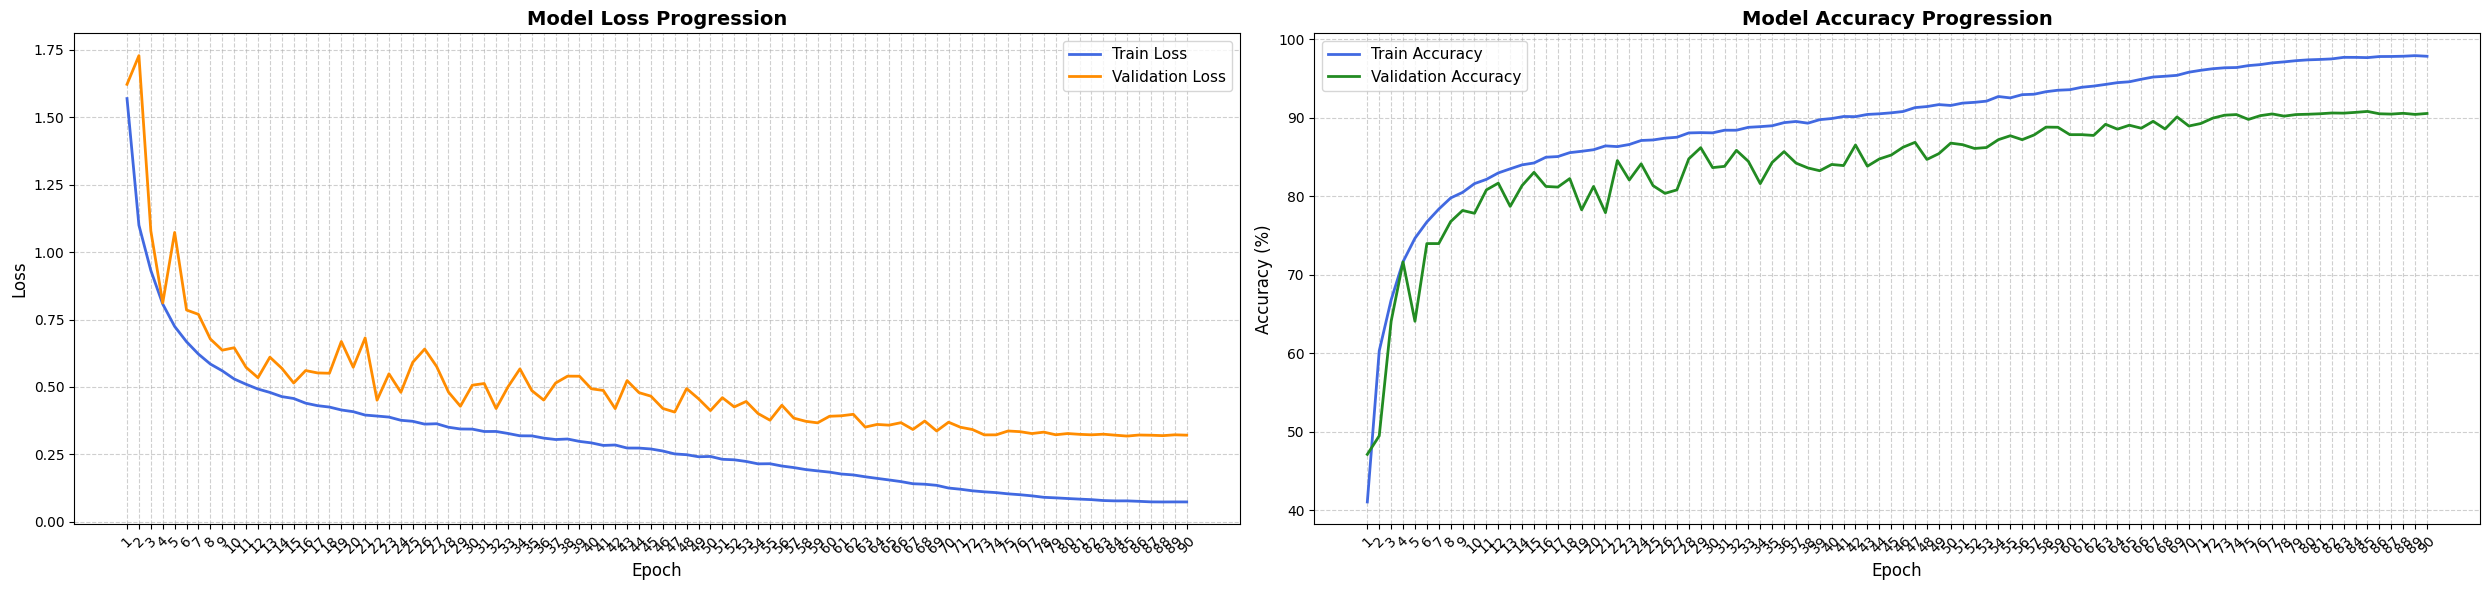

In [21]:
epochs = range(1, len(metrics) + 1)
fig, ax = plt.subplots(1, 2, figsize=(25, 6))

ax[0].plot(epochs, [m["train_loss"] for m in metrics], label="Train Loss", color="royalblue", linewidth=2)
ax[0].plot(epochs, [m["validation_loss"] for m in metrics], label="Validation Loss", color="darkorange", linewidth=2)
ax[0].set_title("Model Loss Progression", fontsize=14, fontweight="bold")
ax[0].set_xlabel("Epoch", fontsize=12)
ax[0].set_ylabel("Loss", fontsize=12)
ax[0].grid(True, linestyle="--", alpha=0.6)
ax[0].legend(fontsize=11)

ax[1].plot(epochs, [100 * m["train_accuracy"] for m in metrics], label="Train Accuracy", color="royalblue", linewidth=2)
ax[1].plot(epochs, [100 * m["validation_accuracy"] for m in metrics], label="Validation Accuracy", color="forestgreen", linewidth=2)
ax[1].set_title("Model Accuracy Progression", fontsize=14, fontweight="bold")
ax[1].set_xlabel("Epoch", fontsize=12)
ax[1].set_ylabel("Accuracy (%)", fontsize=12)
ax[1].grid(True, linestyle="--", alpha=0.6)
ax[1].legend(fontsize=11)

for axis in ax:
    axis.set_xticks(list(epochs))
ax[0].tick_params(axis="x", labelrotation=45)
ax[1].tick_params(axis="x", labelrotation=45)
plt.tight_layout()
plt.show()